In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Data Cleaning

In [2]:
df=pd.read_csv("train.csv")
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [3]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  str    
 3   Delivery_person_Ratings      45593 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

(45593, 20)

In [4]:
for col in df.select_dtypes(include='object').columns.tolist()+df.select_dtypes(include='string').columns.tolist():
    df[col]=df[col].str.strip()
df.replace("NaN",np.nan,inplace=True)
df.isnull().sum()

C:\Users\HP\AppData\Local\Temp\ipykernel_7520\1954069603.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns.tolist()+df.select_dtypes(include='string').columns.tolist():


ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weatherconditions                 0
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken(min)                   0
dtype: int64

In [5]:
df["Delivery_person_Age"]=pd.to_numeric(df["Delivery_person_Age"])
df["Delivery_person_Ratings"]=pd.to_numeric(df["Delivery_person_Ratings"])
df["multiple_deliveries"]=pd.to_numeric(df["multiple_deliveries"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  43862 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         44992 non-null  str    
 13  Vehicle_condition          

In [6]:
df["Weather"]=df['Weatherconditions'].str.replace("conditions","").str.strip()
df["Weather"]=df["Weather"].replace("NaN",np.nan)
df=df.drop(columns="Weatherconditions")

In [7]:
df["Time_taken"] = df["Time_taken(min)"].str.extract(r"(\d+)").astype(int)
df = df.drop(columns="Time_taken(min)")
df["Time_taken"].head()

0    24
1    33
2    26
3    21
4    30
Name: Time_taken, dtype: int64

In [8]:
for c in ["Delivery_person_Age","Delivery_person_Ratings","multiple_deliveries"]:
    df[c]=pd.to_numeric(df[c])
    df[c]=df[c].fillna(df[c].median())

In [9]:
for c in ['Road_traffic_density',"Festival","City","Weather"]:
    df[c]=df[c].fillna(df[c].mode()[0])
    df.isnull().sum()

In [10]:
df.duplicated().sum()

np.int64(0)

# Data Transformation

In [11]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], dayfirst=True)
df["Time_Orderd"] = pd.to_datetime(df["Time_Orderd"], format="%H:%M:%S", errors="coerce")
df["Time_Order_picked"] = pd.to_datetime(df["Time_Order_picked"], format="%H:%M:%S", errors="coerce")
df = df.dropna(subset=["Time_Orderd"])   # drop the 1731 rows with no order time
df.info()

<class 'pandas.DataFrame'>
Index: 43862 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   ID                           43862 non-null  str           
 1   Delivery_person_ID           43862 non-null  str           
 2   Delivery_person_Age          43862 non-null  float64       
 3   Delivery_person_Ratings      43862 non-null  float64       
 4   Restaurant_latitude          43862 non-null  float64       
 5   Restaurant_longitude         43862 non-null  float64       
 6   Delivery_location_latitude   43862 non-null  float64       
 7   Delivery_location_longitude  43862 non-null  float64       
 8   Order_Date                   43862 non-null  datetime64[us]
 9   Time_Orderd                  43862 non-null  datetime64[us]
 10  Time_Order_picked            43862 non-null  datetime64[us]
 11  Road_traffic_density         43862 non-null  str         

In [12]:
df = df.rename(columns={
    "Delivery_person_ID": "rider_id",
    "Delivery_person_Age": "age",
    "Delivery_person_Ratings": "rating",
    "Restaurant_latitude": "rest_lat",
    "Restaurant_longitude": "rest_lon",
    "Delivery_location_latitude": "del_lat",
    "Delivery_location_longitude": "del_lon",
    "Order_Date": "order_date",
    "Time_Orderd": "order_time",
    "Time_Order_picked": "pickup_time",
    "Road_traffic_density": "traffic",
    "Vehicle_condition": "vehicle_condition",
    "Type_of_order": "order_type",
    "Type_of_vehicle": "vehicle",
    "multiple_deliveries": "multi_deliveries",
    "Festival": "festival",
    "City": "city",
    "Weather": "weather",
    "Time_taken": "time_taken",
})
df.columns

Index(['ID', 'rider_id', 'age', 'rating', 'rest_lat', 'rest_lon', 'del_lat',
       'del_lon', 'order_date', 'order_time', 'pickup_time', 'traffic',
       'vehicle_condition', 'order_type', 'vehicle', 'multi_deliveries',
       'festival', 'city', 'weather', 'time_taken'],
      dtype='str')

Distance in km

In [13]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["rest_lat"], df["rest_lon"], df["del_lat"], df["del_lon"])
df["distance_km"].describe()

count    43862.000000
mean        27.170206
std        303.076394
min          1.465067
25%          4.663432
50%          9.220419
75%         13.682165
max       6884.726399
Name: distance_km, dtype: float64

Order hour

In [14]:
df["order_hour"] = df["order_time"].dt.hour

Weekday

In [15]:
df["weekday"] = df["order_date"].dt.day_name()

Is weekend

In [16]:

df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"]).astype(int)

Prep time(minutes)

In [17]:
df["prep_time"] = (df["pickup_time"] - df["order_time"]).dt.total_seconds() / 60
df.loc[df["prep_time"] < 0, "prep_time"] += 1440

Peak hour(1=Yes,0=No)

In [18]:
df["peak_hour"] = df["order_hour"].isin([12, 13, 19, 20, 21]).astype(int)

Time of day group

In [19]:
def day_part(h):
    if h < 12: return "Morning"
    elif h < 17: return "Afternoon"
    elif h < 21: return "Evening"
    else: return "Night"

df["day_part"] = df["order_hour"].apply(day_part)

Distance Group

In [20]:
df["distance_group"] = pd.cut(df["distance_km"], bins=[0, 5, 10, 20, 100],
                              labels=["0-5 km", "5-10 km", "10-20 km", "20+ km"])

Late delivery flag(over 30 min)

In [21]:
df["late"] = (df["time_taken"] > 30).astype(int)

Result

In [22]:
df[["distance_km", "order_hour", "weekday", "is_weekend", "prep_time", "peak_hour", "day_part", "distance_group", "late"]].head()

,distance_km,order_hour,weekday,is_weekend,prep_time,peak_hour,day_part,distance_group,late
0,3.025149,11,Saturday,1,15.0,0,Morning,0-5 km,0
1,20.183530,19,Friday,0,5.0,1,Evening,20+ km,1
2,1.552758,8,Saturday,1,15.0,0,Morning,0-5 km,0
3,7.790401,18,Tuesday,0,10.0,0,Evening,5-10 km,0
4,6.210138,13,Saturday,1,15.0,1,Afternoon,5-10 km,0


# Analysis

Overall summary of delivery time

In [23]:
df["time_taken"].describe()

count    43862.000000
mean        26.293831
std          9.373765
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: time_taken, dtype: float64

Average time by city

In [24]:
df.groupby("city")["time_taken"].mean().sort_values()

city
Urban            23.000000
Metropolitian    27.133123
Semi-Urban       49.737179
Name: time_taken, dtype: float64

Average time by traffic

In [25]:
df.groupby("traffic")["time_taken"].mean().sort_values()

traffic
Low       21.277453
Medium    26.717925
High      27.208468
Jam       31.154348
Name: time_taken, dtype: float64

Average time by weather

In [26]:
df.groupby("weather")["time_taken"].mean().sort_values()

weather
Sunny         21.847517
Stormy        25.858552
Sandstorms    25.890734
Windy         26.104537
Fog           28.931915
Cloudy        28.939638
Name: time_taken, dtype: float64

Multiple deliveries effect

In [27]:
df.groupby("multi_deliveries")["time_taken"].mean()

multi_deliveries
0.0    22.865028
1.0    26.724787
2.0    40.427604
3.0    47.816327
Name: time_taken, dtype: float64

Fastest vehicle type

In [28]:
df.groupby("vehicle")["time_taken"].mean().sort_values()

vehicle
electric_scooter    24.407187
scooter             24.467574
motorcycle          27.600905
Name: time_taken, dtype: float64

Festival vs normal days

In [29]:
df.groupby("festival")["time_taken"].mean()

festival
No     25.911057
Yes    45.501750
Name: time_taken, dtype: float64

Peak hour vs non-peak

In [30]:
df.groupby("peak_hour")["time_taken"].mean()

peak_hour
0    23.933265
1    30.614933
Name: time_taken, dtype: float64

Traffic and weather together 

In [31]:
df.pivot_table(values="time_taken", index="traffic", columns="weather", aggfunc="mean")

weather,Cloudy,Fog,Sandstorms,Stormy,Sunny,Windy
traffic,,,,,,
High,29.016552,28.415789,27.693997,27.781818,23.319001,26.977716
Jam,36.696374,36.798485,29.963964,29.834069,23.045515,30.212108
Low,22.232256,22.309881,20.348617,20.665019,21.455638,20.657591
Medium,28.491895,28.073521,27.783458,27.687326,20.233429,27.839493


Percentage of late orders

In [32]:
df["late"].mean() * 100

np.float64(29.82992111622817)

Festival average

In [33]:
df.groupby("festival")["time_taken"].mean().round(1)

festival
No     25.9
Yes    45.5
Name: time_taken, dtype: float64

Orders per city type

In [34]:
df["city"].value_counts()

city
Metropolitian    33946
Urban             9760
Semi-Urban         156
Name: count, dtype: int64

# Visualization

Delivery time distribution

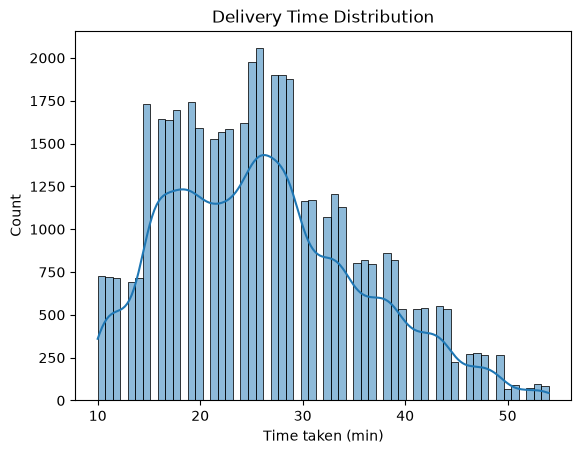

In [35]:
sns.histplot(df["time_taken"], kde=True)
plt.title("Delivery Time Distribution")
plt.xlabel("Time taken (min)")
plt.show()

Traffic vs delivery time

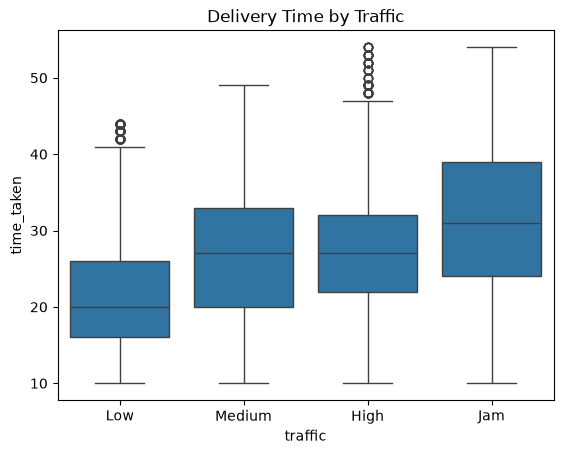

In [36]:
sns.boxplot(x="traffic", y="time_taken", data=df, order=["Low", "Medium", "High", "Jam"])
plt.title("Delivery Time by Traffic")
plt.show()

City comparison

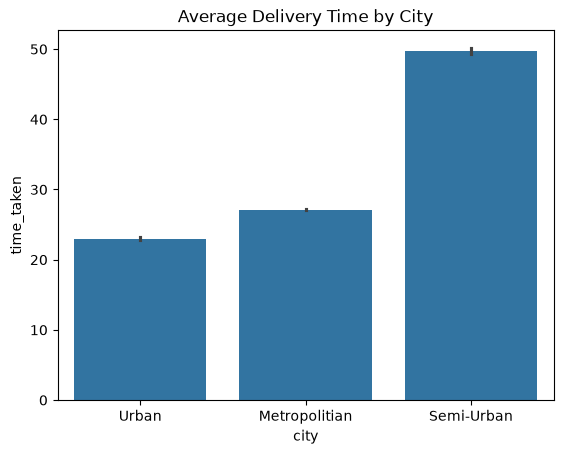

In [37]:
sns.barplot(x="city", y="time_taken", data=df)
plt.title("Average Delivery Time by City")
plt.show()

Correlation heatmap

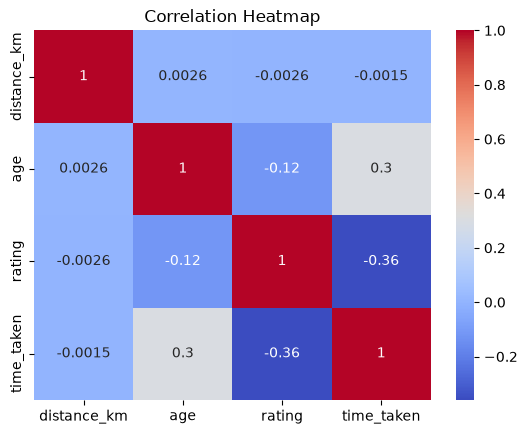

In [38]:
sns.heatmap(df[["distance_km", "age", "rating", "time_taken"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Insights & Recommendations

In [39]:
print("Average delivery time:", round(df["time_taken"].mean(), 1), "min")
print("Late orders (>30 min):", round(df["late"].mean() * 100, 1), "%")
print()
print(df.groupby("traffic")["time_taken"].mean().round(1))
print()
print(df.groupby("weather")["time_taken"].mean().round(1))
print()
print(df.groupby("multi_deliveries")["time_taken"].mean().round(1))
print()
print(df.groupby("festival")["time_taken"].mean().round(1))
print()
print(df.groupby("city")["time_taken"].mean().round(1))

Average delivery time: 26.3 min
Late orders (>30 min): 29.8 %

traffic
High      27.2
Jam       31.2
Low       21.3
Medium    26.7
Name: time_taken, dtype: float64

weather
Cloudy        28.9
Fog           28.9
Sandstorms    25.9
Stormy        25.9
Sunny         21.8
Windy         26.1
Name: time_taken, dtype: float64

multi_deliveries
0.0    22.9
1.0    26.7
2.0    40.4
3.0    47.8
Name: time_taken, dtype: float64

festival
No     25.9
Yes    45.5
Name: time_taken, dtype: float64

city
Metropolitian    27.1
Semi-Urban       49.7
Urban            23.0
Name: time_taken, dtype: float64


## Key Insights
1. The average delivery takes 26.3 minutes, and 29.8% of orders take more than 30 minutes.
2. Multiple deliveries have the biggest effect: time rises from 22.9 min (no other orders) to 40.4 min (2 orders) and 47.8 min (3 orders).
3. Festival days are much slower: 45.5 min vs 25.9 min on normal days (about 20 min longer).
4. Traffic: Jam is the slowest at 31.2 min, versus 21.3 min in Low traffic.
5. Weather: Cloudy and Fog orders take about 28.9 min, versus 21.8 min on Sunny days.
6. Semi-Urban averages 49.7 min, but it has only 156 orders, so this is based on a small sample.

## Recommendations
- Add extra riders and incentives on festival days.
- Cap riders at 1 extra order at a time.
- Add rider incentives during Jam traffic and in Fog or Cloudy weather.
- Collect more Semi-Urban data before making decisions for that area.
- Show longer delivery estimates on festival days and in bad traffic or weather.